In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

In [2]:
data_dir = Path.cwd()
if not any(data_dir.glob("*.dat")):
    data_dir = data_dir / "SWT"

dat_files = sorted(data_dir.glob("*.dat"))
if not dat_files:
    raise FileNotFoundError(f"Aucun fichier .dat trouvé dans {data_dir}")

matrices = {}
for dat_file in dat_files:
    values = np.loadtxt(dat_file, dtype=float)
    if values.shape != (19, 20 * 200):
        raise ValueError(
            f"{dat_file.name}: forme {values.shape} inattendue; "
            "attendu (19, 4000)"
        )

    # Les lignes du fichier deviennent le dernier axe de la matrice.
    matrices[dat_file.stem] = values.reshape(19, 200, 20).transpose(2, 1, 0)

for name, matrix in matrices.items():
    print(f"{name}: {matrix.shape}")

Eps11: (20, 200, 19)
Eps12: (20, 200, 19)
Eps22: (20, 200, 19)
Eps33: (20, 200, 19)
S11: (20, 200, 19)
S12: (20, 200, 19)
S22: (20, 200, 19)
S33: (20, 200, 19)


In [40]:
next(iter(matrices))

'Eps11'

In [41]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

first_file = "S11"
time_series = matrices[first_file]

fig, ax = plt.subplots(figsize=(12, 4))
image = ax.imshow(
    time_series[:, :, 0],
    aspect="auto",
    origin="lower",
    cmap="viridis",
    vmin=np.min(time_series),
    vmax=np.max(time_series),
)
title = ax.set_title(f"{first_file} - évolution temporelle (étape 1/{time_series.shape[2]})")
ax.set_xlabel("Repetition (200)")
ax.set_ylabel("Valeur dans la sequence (20)")
fig.colorbar(image, ax=ax, label="Valeur")
fig.tight_layout()

def update(frame):
    image.set_data(time_series[:, :, frame])
    title.set_text(
        f"{first_file} - évolution temporelle (étape {frame + 1}/{time_series.shape[2]})"
    )
    return image, title

animation = FuncAnimation(
    fig,
    update,
    frames=time_series.shape[2],
    interval=300,
    repeat=True,
    blit=False,
)
plt.close(fig)
HTML(animation.to_jshtml())

In [17]:
matrices.keys()

dict_keys(['Eps11', 'Eps12', 'Eps22', 'Eps33', 'S11', 'S12', 'S22', 'S33'])

In [31]:
point = np.array([0,0])

In [32]:
np.max(matrices["S11"])

np.float64(557869.32)

In [35]:
sigma_max = np.zeros((20,200,2))
for i in range(20):
    for j in range(200):
        point = np.array([i,j])
        L_max = []
        for theta in np.linspace(0, 2*np.pi, 360):
            sigma_theta = (
                matrices["S11"][point[0], point[1], :]
                * np.cos(theta) ** 2
                + matrices["S22"][point[0], point[1], :]
                * np.sin(theta) ** 2
                - matrices["S12"][point[0], point[1], :] * np.sin(2*theta)
            )
            L_max.append((theta, np.max(sigma_theta)))
        sigma_max[point[0], point[1], 0], sigma_max[point[0], point[1], 1] = max(L_max, key=lambda x: x[1])

In [37]:
delta_eps = np.zeros((20,200))
for i in range(20):
    for j in range(200):
        eps_theta = (
                matrices["Eps11"][i,j, :]
                * np.cos(sigma_max[i,j, 0]) ** 2
                + matrices["Eps22"][i,j, :]
                * np.sin(sigma_max[i,j, 0]) ** 2
                - matrices["Eps12"][i,j, :] * np.sin(2*sigma_max[i,j, 0])
            )
        delta_eps[i,j] = np.max(eps_theta) - np.min(eps_theta)

In [ ]:
SWT_Faux = delta_eps*sigma_max[:,:,1]*0.5

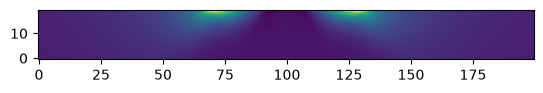

In [42]:
result = np.zeros((20,200, 360))
for i in range(20):
    for j in range(200):
        point = np.array([i,j])
        L_max = []
        for k, theta in enumerate(np.linspace(0, 2*np.pi, 360)):
            sigma_theta = (
                matrices["S11"][point[0], point[1], :]
                * np.cos(theta) ** 2
                + matrices["S22"][point[0], point[1], :]
                * np.sin(theta) ** 2
                + matrices["S12"][point[0], point[1], :] * np.sin(2*theta)
            )
            sigma_max_t = np.max(sigma_theta)

            eps_theta = (
                            matrices["Eps11"][i,j, :]
                            * np.cos(theta) ** 2
                            + matrices["Eps22"][i,j, :]
                            * np.sin(theta) ** 2
                            + matrices["Eps12"][i,j, :] * np.sin(2*theta)
                        )
            delta_eps_theta = np.max(eps_theta) - np.min(eps_theta)
            result[i, j, k] = delta_eps_theta*sigma_max_t*0.5
SWT = np.max(result, axis=2)

#Affiche SWT
plt.imshow(SWT, cmap='viridis', origin='lower')